In [1]:
# %pip install pandas numpy matplotlib lightgbm scikit-learn
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMRegressor
from matplotlib.patches import Patch
from sklearn.metrics import mean_absolute_error, mean_squared_error

csv_name = "beijing_multisite_features.csv"
paths = [Path("data/sample") / csv_name, Path("../data/sample") / csv_name, Path(csv_name)]
data_path = next((path for path in paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"Đặt {csv_name} trong data/sample/ hoặc cạnh notebook.")

raw = pd.read_csv(data_path, dtype={"station_id": "string"})
print("Kích thước dữ liệu:", raw.shape)
display(raw.head())

Kích thước dữ liệu: (2016, 7)


,station_id,event_time,pm25_ug_m3,temperature_c,relative_humidity_pct,wind_speed_m_s,wind_direction_deg
0,beijing_Aotizhongxin,2015-11-15T00:00:00Z,210.0,4.8,99.304775,0.1,45.0
1,beijing_Aotizhongxin,2015-11-15T01:00:00Z,177.0,6.4,99.313637,0.4,22.5
2,beijing_Aotizhongxin,2015-11-15T02:00:00Z,176.0,8.9,80.911652,1.6,22.5
3,beijing_Aotizhongxin,2015-11-15T03:00:00Z,221.0,9.5,74.024899,0.8,315.0
4,beijing_Aotizhongxin,2015-11-15T04:00:00Z,225.0,11.2,67.012964,1.8,45.0


In [2]:
weather = ["temperature_c", "relative_humidity_pct", "wind_speed_m_s", "wind_direction_deg"]
keys = ["station_id", "event_time"]
df = raw[keys + ["pm25_ug_m3"] + weather].copy()
df["event_time"] = pd.to_datetime(df["event_time"], utc=True)
assert df[keys].notna().all().all()
assert not df.duplicated(keys).any(), "Trùng khóa trạm và giờ"
df = df.sort_values(keys).reset_index(drop=True)
gaps = df.groupby("station_id")["event_time"].diff().dropna()
assert gaps.eq(pd.Timedelta(hours=1)).all(), "Cần giữ đủ lưới giờ của từng trạm"
display(df.isna().sum().to_frame("Số ô thiếu"))

,Số ô thiếu
station_id,0
event_time,0
pm25_ug_m3,26
temperature_c,0
relative_humidity_pct,0
wind_speed_m_s,0
wind_direction_deg,14


## 3. Tạo lag và nhãn theo từng trạm



In [3]:
by_station = df.groupby("station_id")
local_time = df["event_time"].dt.tz_convert("Asia/Shanghai")
df["hour"] = local_time.dt.hour
df["dayofweek"] = local_time.dt.dayofweek
lags = [1, 2, 3, 6, 12, 24]
for lag in lags:
    df[f"pm25_lag{lag}"] = by_station["pm25_ug_m3"].shift(lag)
for col in weather:
    df[f"{col}_lag1"] = by_station[col].shift(1)

df["target"] = by_station["pm25_ug_m3"].shift(-1)
df["target_time"] = df["event_time"] + pd.Timedelta(hours=1)
features_base = ["pm25_ug_m3", "hour", "dayofweek"] + [f"pm25_lag{lag}" for lag in lags]
weather_features = [f"{col}_lag1" for col in weather]
features = features_base + weather_features

## 4. Xử lý thiếu

In [4]:
missing_current = df["pm25_ug_m3"].isna()
missing_target = df["target"].isna()
print("Thiếu PM2.5 hiện tại:", missing_current.sum())
print("Có PM2.5 hiện tại nhưng thiếu nhãn:", ((~missing_current) & missing_target).sum())
data = df.dropna(subset=["pm25_ug_m3", "target"]).copy()
print("Tổng số dòng bị loại:", len(df) - len(data))
print("Số dòng còn lại:", len(data))
display(data[features].isna().sum().to_frame("NaN đầu vào còn lại"))

Thiếu PM2.5 hiện tại: 26
Có PM2.5 hiện tại nhưng thiếu nhãn: 33
Tổng số dòng bị loại: 59
Số dòng còn lại: 1957


,NaN đầu vào còn lại
pm25_ug_m3,0
hour,0
dayofweek,0
pm25_lag1,33
pm25_lag2,49
pm25_lag3,60
pm25_lag6,95
pm25_lag12,157
pm25_lag24,297
temperature_c_lag1,12


## 5. Chia train/test theo giờ nhãn



In [5]:
cutoff = pd.Timestamp("2015-11-20", tz="UTC")
train = data[data.target_time < cutoff]
test = data[data.target_time >= cutoff]
assert not train.empty and not test.empty
assert train.target_time.max() < test.target_time.min()

print("Số mẫu train:", len(train))
print("Số mẫu test:", len(test))
print("Nhãn train cuối (UTC):", train.target_time.max())
print("Nhãn test đầu (UTC):", test.target_time.min())

Số mẫu train: 1415
Số mẫu test: 542
Nhãn train cuối (UTC): 2015-11-19 23:00:00+00:00
Nhãn test đầu (UTC): 2015-11-20 00:00:00+00:00


## 6. Huấn luyện và dự báo

In [6]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    n_jobs=2,
    verbosity=-1,
)
model.fit(train[features], train.target)
pred = pd.DataFrame(
    {
        "station_id": test.station_id,
        "target_time": test.target_time,
        "actual": test.target,
        "Persistence": test.pm25_ug_m3,
        "LightGBM": np.maximum(model.predict(test[features]), 0),
    }
)
assert pred.notna().all().all()

display(pred.head())

imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
display(imp.to_frame("Độ quan trọng (split)"))

,station_id,target_time,actual,Persistence,LightGBM
119,beijing_Aotizhongxin,2015-11-20 00:00:00+00:00,29.0,32.0,42.796761
120,beijing_Aotizhongxin,2015-11-20 01:00:00+00:00,40.0,29.0,32.515947
121,beijing_Aotizhongxin,2015-11-20 02:00:00+00:00,51.0,40.0,47.655993
122,beijing_Aotizhongxin,2015-11-20 03:00:00+00:00,60.0,51.0,47.033123
123,beijing_Aotizhongxin,2015-11-20 04:00:00+00:00,74.0,60.0,47.924334


,Độ quan trọng (split)
pm25_ug_m3,664
pm25_lag1,579
pm25_lag3,421
pm25_lag6,409
pm25_lag2,388
relative_humidity_pct_lag1,302
pm25_lag12,294
temperature_c_lag1,290
wind_speed_m_s_lag1,232
wind_direction_deg_lag1,203


## 7. MAE và RMSE

In [7]:
rows = []
for name in ["Persistence", "LightGBM"]:
    rows.append(
        {
            "Model": name,
            "MAE": mean_absolute_error(pred.actual, pred[name]),
            "RMSE": np.sqrt(mean_squared_error(pred.actual, pred[name])),
        }
    )
results = pd.DataFrame(rows).set_index("Model")

display(results.round(3))
improvement = (1 - results.loc["LightGBM"] / results.loc["Persistence"]) * 100
print("Giảm MAE (%):", round(improvement["MAE"], 2))
print("Giảm RMSE (%):", round(improvement["RMSE"], 2))

Giảm MAE (%): -39.66
Giảm RMSE (%): -26.13


,MAE,RMSE
Model,,
Persistence,6.742,9.593
LightGBM,9.415,12.099


## 8. Sai số theo tháng



In [8]:
pred["month"] = pred.target_time.dt.tz_convert("Asia/Shanghai").dt.strftime("%Y-%m")
rows = []
for month, group in pred.groupby("month"):
    for name in ["Persistence", "LightGBM"]:
        rows.append(
            {
                "Month": month,
                "Model": name,
                "N": len(group),
                "MAE": mean_absolute_error(group.actual, group[name]),
                "RMSE": np.sqrt(mean_squared_error(group.actual, group[name])),
            }
        )
monthly = pd.DataFrame(rows)

display(monthly.round(3))

,Month,Model,N,MAE,RMSE
0,2015-11,Persistence,542,6.742,9.593
1,2015-11,LightGBM,542,9.415,12.099


## 9. Biểu đồ sai số theo tháng

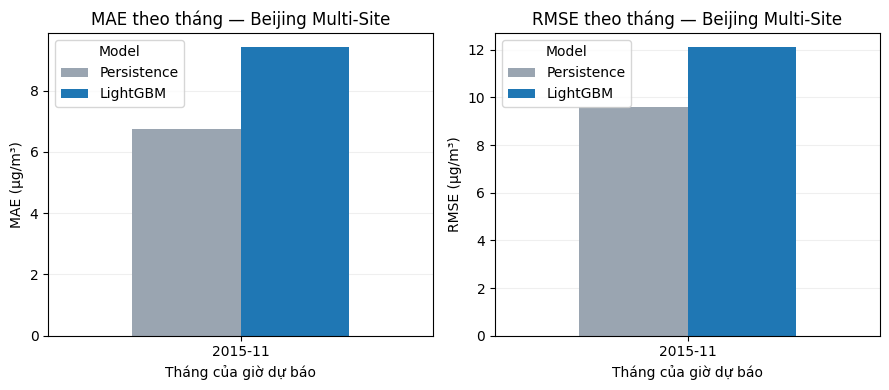

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = monthly.pivot(index="Month", columns="Model", values=metric)
    table[["Persistence", "LightGBM"]].plot.bar(
        ax=ax, rot=0, color=["#9aa5b1", "#1f77b4"], width=0.65
    )
    ax.set_title(f"{metric} theo tháng — Beijing Multi-Site")
    ax.set_xlabel("Tháng của giờ dự báo")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 10. Đóng góp đặc trưng

,Đóng góp (%)
Khí tượng,11.1
PM2.5 và lag,81.6
Thời gian,7.2


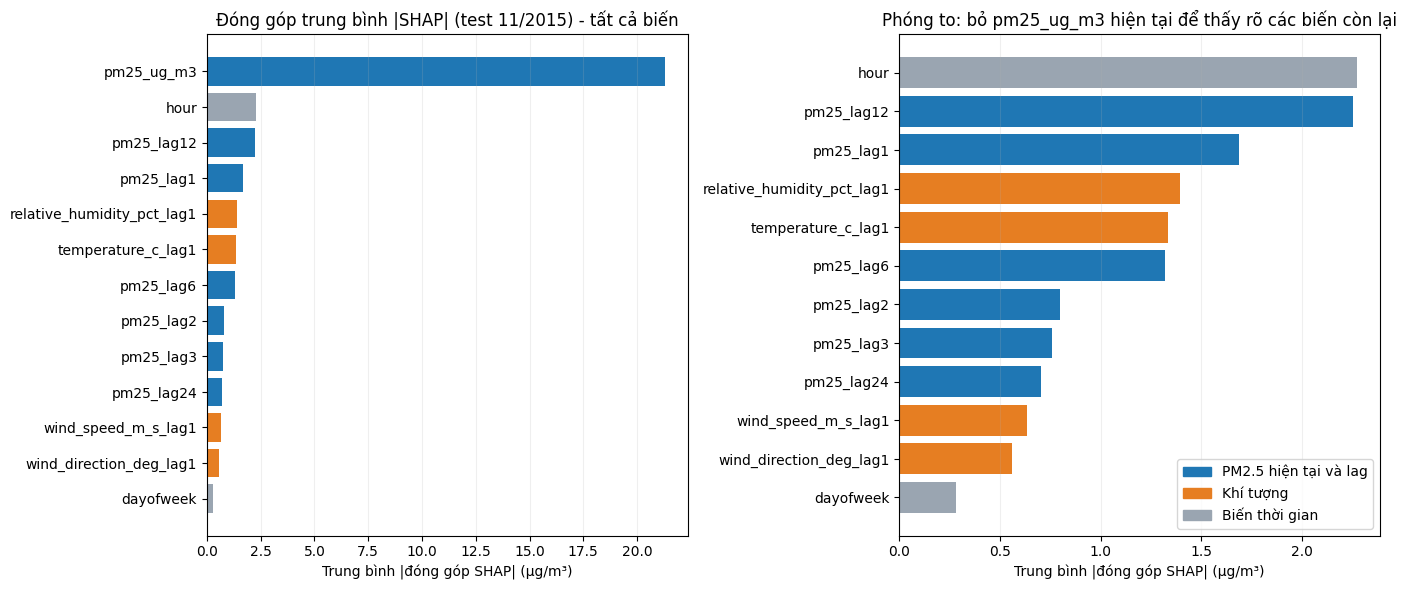

In [10]:
contrib = model.booster_.predict(test[features], pred_contrib=True)[:, :-1]
contrib = pd.DataFrame(contrib, index=test.index, columns=features)
mean_abs = contrib.abs().mean().sort_values()


def group_color(f):
    if f in weather_features:
        return "#e67e22"
    if f in ["hour", "dayofweek"]:
        return "#9aa5b1"
    return "#1f77b4"


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(mean_abs.index, mean_abs.values, color=[group_color(f) for f in mean_abs.index])
axes[0].set_title("Đóng góp trung bình |SHAP| (test 11/2015) - tất cả biến")
zoom = mean_abs.drop("pm25_ug_m3")
axes[1].barh(zoom.index, zoom.values, color=[group_color(f) for f in zoom.index])
axes[1].set_title("Phóng to: bỏ pm25_ug_m3 hiện tại để thấy rõ các biến còn lại")
for ax in axes:
    ax.set_xlabel("Trung bình |đóng góp SHAP| (µg/m³)")
    ax.grid(axis="x", alpha=0.2)

axes[1].legend(
    handles=[
        Patch(color="#1f77b4", label="PM2.5 hiện tại và lag"),
        Patch(color="#e67e22", label="Khí tượng"),
        Patch(color="#9aa5b1", label="Biến thời gian"),
    ],
    loc="lower right",
)
plt.tight_layout()
plt.show()

group = pd.Series(
    {
        f: "Khí tượng"
        if f in weather_features
        else "Thời gian"
        if f in ["hour", "dayofweek"]
        else "PM2.5 và lag"
        for f in features
    }
)
display(
    (contrib.abs().mean().groupby(group).sum() / contrib.abs().mean().sum() * 100)
    .round(1)
    .to_frame("Đóng góp (%)")
)